# Semana 5 — Controle Fuzzy Adaptativo do SMA: Sintonia com Optuna
### Otimização dos consequentes Fuzzy e avaliação comparativa no Permutation Flow Shop

**Objetivo:** avaliar se a sintonia das intensidades do controlador e da janela de estagnação melhora a minimização do *Total Tardiness*. São comparados o SMA com reinicialização fixa, o Fuzzy original e o Fuzzy ajustado por Optuna. A avaliação de soluções permanece exclusivamente a cargo da `FlowShopEngine` (PFS).

## 1. Delineamento experimental

O controle Fuzzy modifica a taxa de reinicialização `z` a cada geração. Os nove consequentes originais são preservados como matriz de referência; o Optuna procura **escalas independentes para os deslocamentos positivos e negativos**, além da **janela de estagnação**. A estrutura linguística e as funções de pertinência permanecem fixas.

| Etapa | Procedimento | Dados utilizados |
|:--|:--|:--|
| Referência estática | `z_base` e população da configuração de referência | Valores já determinados |
| Sintonia do Fuzzy | Otimização dos três parâmetros do controlador | Sementes exclusivas de sintonia |
| Seleção da configuração | Menor média de Total Tardiness entre sementes de sintonia | Não utiliza as sementes do teste |
| Avaliação final | SMA fixo × Fuzzy original × Fuzzy tunado | Novas sementes, mesmo orçamento real |
| Interpretação | Desempenho, tempo, trajetória de `z`, Wilcoxon pareado | Relatório por instância |

A seleção é **específica para cada instância**. Como estas instâncias já foram analisadas em experimentos anteriores, o teste é uma validação exploratória com novas sementes, não uma demonstração de generalização a problemas inéditos.

In [1]:
import sys, subprocess, importlib.util, json, zipfile, time, warnings
if importlib.util.find_spec("optuna") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "optuna"])
import optuna
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from IPython.display import display

# True: experimento de entrega; False: execução de verificação rápida.
EXECUCAO_COMPLETA = True
SEMENTE_GLOBAL = 2026
np.random.seed(SEMENTE_GLOBAL)
plt.rcParams.update({'figure.dpi':120, 'font.size':10, 'axes.grid':True, 'grid.alpha':0.18})
OUT = Path('/kaggle/working/semana5_fuzzy_optuna' if Path('/kaggle/working').exists() else '/mnt/data/semana5_fuzzy_optuna')
OUT.mkdir(parents=True, exist_ok=True)
CONFIG = {
    'avaliacoes': 3000 if EXECUCAO_COMPLETA else 200,
    'sementes': [3109,3203,3301,3407,3511,3607,3701,3803,3907,4001,4103,4201,4307,4409,4507,4603,4703,4801,4903,5003] if EXECUCAO_COMPLETA else [3109,3203],
    'sementes_sintonia': [1103,1207,1301] if EXECUCAO_COMPLETA else [1103,1207],
    'trials_optuna': 50 if EXECUCAO_COMPLETA else 2,
    'avaliacoes_sintonia': 3000 if EXECUCAO_COMPLETA else 200,
    'janela_estagnacao': 12,
    'intensidade_controle': 1.0,
    'intervalo_z': (0.0, 0.15)
}
print('Modo:', 'EXPERIMENTO COMPLETO' if EXECUCAO_COMPLETA else 'VERIFICAÇÃO')
display(pd.DataFrame([{'configuração':k,'valor':str(v)} for k,v in CONFIG.items()]))
print('Arquivos:',OUT)

Modo: EXPERIMENTO COMPLETO


,configuração,valor
0,avaliacoes,3000
1,sementes,"[3109, 3203, 3301, 3407, 3511, 3607, 3701, 380..."
2,sementes_sintonia,"[1103, 1207, 1301]"
3,trials_optuna,50
4,avaliacoes_sintonia,3000
5,janela_estagnacao,12
6,intensidade_controle,1.0
7,intervalo_z,"(0.0, 0.15)"


Arquivos: /kaggle/working/semana5_fuzzy_optuna


## 2. Instâncias, função objetivo e configuração estática

A primeira linha das instâncias informa o número de trabalhos e máquinas. A segunda linha do arquivo não é utilizada no PFS adotado neste estudo. A função objetivo contabiliza o atraso positivo de cada trabalho, usando a mesma sequência de trabalhos em todas as máquinas.

\[
TT(\pi)=\sum_{j=1}^{n}\max(0,C_j(\pi)-d_j).
\]

Os hiperparâmetros fixos foram selecionados por Optuna na etapa anterior, com 50 trials para cada instância. Assim, o Fuzzy usa um valor de referência `z_base` já determinado, com uma nova busca exclusiva para os parâmetros do controlador, sem utilizar as sementes de teste.

In [2]:
BASES = [Path('/kaggle/input/datasets/caiomoreiraban/dpfsp-dd/DPFSP_DD'),
         Path('/kaggle/input/dpfsp-dd/DPFSP_DD'),Path('/mnt/data/DPFSP_DD')]
DATASET_DIR = next((p for p in BASES if p.is_dir() and any(p.rglob('*.txt'))),None)
if DATASET_DIR is None and Path('/mnt/data/DPFSP_DD.zip').exists():
    with zipfile.ZipFile('/mnt/data/DPFSP_DD.zip') as zf:
        zf.extractall('/mnt/data')
    DATASET_DIR=Path('/mnt/data/DPFSP_DD')
if DATASET_DIR is None and Path('/kaggle/input').exists():
    for p in Path('/kaggle/input').rglob('Ta001_2.txt'):
        DATASET_DIR=next((q for q in p.parents if q.name=='DPFSP_DD'),p.parent)
        break
if DATASET_DIR is None:
    raise FileNotFoundError('Adicione o dataset DPFSP_DD em Input no Kaggle.')

class FlowShopEngine:
    def __init__(self,n_jobs,n_machines,proc_times,due_dates):
        self.n_jobs=n_jobs;self.n_machines=n_machines
        self.proc_times=np.asarray(proc_times,dtype=np.int32)
        self.due_dates=np.asarray(due_dates,dtype=np.int32)
        self.cfo_count=0

    @staticmethod
    def carregar_instancia_txt(caminho):
        with open(caminho,encoding='utf-8') as f:
            linhas=[linha.strip() for linha in f if linha.strip()]
        n,m=map(int,linhas[0].split())
        mat=np.zeros((n,m),dtype=np.int32)
        for j in range(n):
            pares=list(map(int,linhas[j+2].split()))
            if len(pares)!=2*m:raise ValueError(f'Formato inválido no trabalho {j}')
            maquinas=pares[::2];tempos=pares[1::2]
            if sorted(maquinas)!=list(range(m)):raise ValueError('Índices de máquinas inválidos')
            mat[j,maquinas]=tempos
        idx=next((i for i,s in enumerate(linhas) if s.lower()=='duedate'),None)
        if idx is None:raise ValueError('Campo Duedate ausente')
        due=np.asarray([int(v) for v in linhas[idx+1:idx+1+n]],dtype=np.int32)
        if len(due)!=n:raise ValueError('Prazos incompletos')
        return n,m,mat,due

    def bucket_sort_decode(self,keys):
        return np.argsort(np.asarray(keys)[:self.n_jobs],kind='stable')

    def evaluate_with_permutation(self,permutation,objective='Tardiness'):
        self.cfo_count+=1
        seq=np.asarray(permutation,dtype=int)
        if not np.array_equal(np.sort(seq),np.arange(self.n_jobs)):
            raise ValueError('Permutação inválida')
        term=np.zeros((self.n_machines,self.n_jobs),dtype=float)
        for maquina in range(self.n_machines):
            disponivel=0.
            for j in seq:
                disponivel=max(disponivel,term[maquina-1,j] if maquina>0 else 0.)+self.proc_times[j,maquina]
                term[maquina,j]=disponivel
        if objective=='Makespan':return float(term[-1].max())
        if objective=='Tardiness':return float(np.maximum(term[-1]-self.due_dates,0).sum())
        raise ValueError('Objetivo desconhecido')

    def evaluate(self,keys,mode='PFS',objective='Tardiness'):
        if mode!='PFS':raise ValueError('Somente PFS')
        return self.evaluate_with_permutation(self.bucket_sort_decode(keys),objective)

INSTANCIAS=['Large/Ta001_2.txt','Large/Ta041_3.txt']
PARAMETROS_SMA={
    'Large/Ta001_2.txt':{'populacao':40,'z':0.0008499388875837788},
    'Large/Ta041_3.txt':{'populacao':50,'z':0.13428290269269394}
}
ENGINES={nome:FlowShopEngine(*FlowShopEngine.carregar_instancia_txt(DATASET_DIR/nome)) for nome in INSTANCIAS}
linhas=[]
for nome,e in ENGINES.items():
    pars=PARAMETROS_SMA[nome]
    linhas.append({'instância':nome,'trabalhos':e.n_jobs,'máquinas':e.n_machines,**pars})
    keys=np.random.default_rng(1).random(e.n_jobs)
    assert e.evaluate(keys)==e.evaluate_with_permutation(e.bucket_sort_decode(keys))
display(pd.DataFrame(linhas).round(5))
print('Leitura e equivalência de avaliações: OK')

,instância,trabalhos,máquinas,populacao,z
0,Large/Ta001_2.txt,20,5,40,0.00085
1,Large/Ta041_3.txt,50,10,50,0.13428


Leitura e equivalência de avaliações: OK


## 3. Inferência Fuzzy e parâmetros ajustáveis

A diversidade `D` é a fração média de posições diferentes da melhor permutação; a estagnação `E` é o número de gerações sem melhoria dividido pela janela escolhida. As entradas ficam em `[0,1]`.

O sistema de Sugeno utiliza nove regras, com funções de pertinência triangulares e trapezoidais. O deslocamento é uma média ponderada dos consequentes; a saída final é `z_t = clip(z_base + Δz, 0, 0,15)`.

A sintonia não altera a interpretação das regras: ajusta separadamente a **magnitude das ações positivas** (`escala_positiva`) e das **ações negativas** (`escala_negativa`), além do tempo necessário para classificar a busca como estagnada (`janela_estagnacao`). Os valores originais equivalem a escalas 1 e janela 12.

In [3]:
def triangular(x,a,b,c):
    x=np.asarray(x,dtype=float)
    return np.maximum(0.,np.minimum((x-a)/max(b-a,1e-12),(c-x)/max(c-b,1e-12)))

def trapezoidal(x,a,b,c,d):
    x=np.asarray(x,dtype=float)
    subida=np.where(x>=b,1.,(x-a)/max(b-a,1e-12))
    descida=np.where(x<=c,1.,(d-x)/max(d-c,1e-12))
    return np.clip(np.minimum(subida,descida),0.,1.)

def pertinencias(x):
    return {
        'Baixa':trapezoidal(x,0.,0.,0.20,0.50),
        'Média':triangular(x,0.20,0.50,0.80),
        'Alta':trapezoidal(x,0.50,0.80,1.,1.)
    }

# Consequentes de ordem zero: deslocamento de z em pontos de probabilidade.
# Linhas: diversidade, colunas: estagnação.
REGRAS=pd.DataFrame(
    [[0.000,0.030,0.065],
     [-0.020,0.000,0.040],
     [-0.040,-0.020,0.010]],
    index=['Baixa','Média','Alta'],columns=['Baixa','Média','Alta']
)

def controlador_fuzzy(diversidade,estagnacao,z_base,intensidade=1.,escala_positiva=1.,escala_negativa=1.):
    mu_d=pertinencias(np.clip(diversidade,0,1))
    mu_e=pertinencias(np.clip(estagnacao,0,1))
    pesos=[];valores=[]
    for div in REGRAS.index:
        for est in REGRAS.columns:
            ativacao=float(min(mu_d[div],mu_e[est]))
            pesos.append(ativacao)
            valor=float(REGRAS.loc[div,est])
            valores.append(valor*(escala_positiva if valor>=0 else escala_negativa))
    soma=sum(pesos)
    delta=float(np.dot(pesos,valores)/soma) if soma>0 else 0.0
    return float(np.clip(z_base+intensidade*delta,*CONFIG['intervalo_z']))

print('Base de regras: Δz (probabilidade absoluta)')
display(REGRAS.rename_axis('Diversidade / Estagnação').style.format('{:+.3f}'))
assert 0<=controlador_fuzzy(.2,.9,.03)<=.15
assert controlador_fuzzy(.2,.9,.03)>controlador_fuzzy(.9,.1,.03)
print('Regras básicas verificadas.')

Base de regras: Δz (probabilidade absoluta)


,Baixa,Média,Alta
Diversidade / Estagnação,,,
Baixa,+0.000,+0.030,+0.065
Média,-0.020,+0.000,+0.040
Alta,-0.040,-0.020,+0.010


Regras básicas verificadas.


### 3.1. Funções de pertinência

Os gráficos mostram os graus de pertinência atribuídos a cada entrada. As sobreposições garantem transições graduais entre os termos linguísticos; as curvas não representam probabilidades e não precisam somar 1.

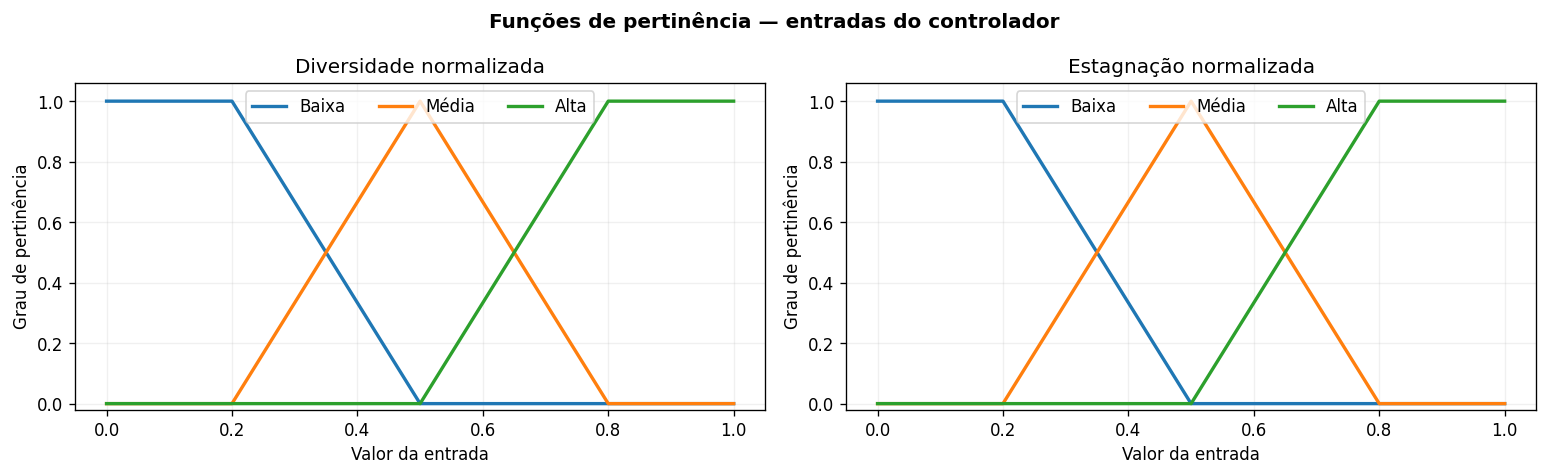

In [4]:
xx=np.linspace(0,1,501)
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax,titulo in zip(axs,['Diversidade normalizada','Estagnação normalizada']):
    for nome,v in pertinencias(xx).items():ax.plot(xx,v,label=nome,lw=2)
    ax.set(title=titulo,xlabel='Valor da entrada',ylabel='Grau de pertinência',ylim=(-.02,1.06))
    ax.legend(loc='upper center',ncol=3)
fig.suptitle('Funções de pertinência — entradas do controlador',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'01_funcoes_pertinencia.png',bbox_inches='tight');plt.show()

### 3.2. Superfície de controle

A superfície mostra a variação esperada de `z` para diferentes estados do SMA. O gráfico utiliza apenas o deslocamento `Δz`, antes do corte imposto ao intervalo permitido de `z`; assim, pode ser aplicado a ambas as instâncias, mesmo com valores de referência distintos.

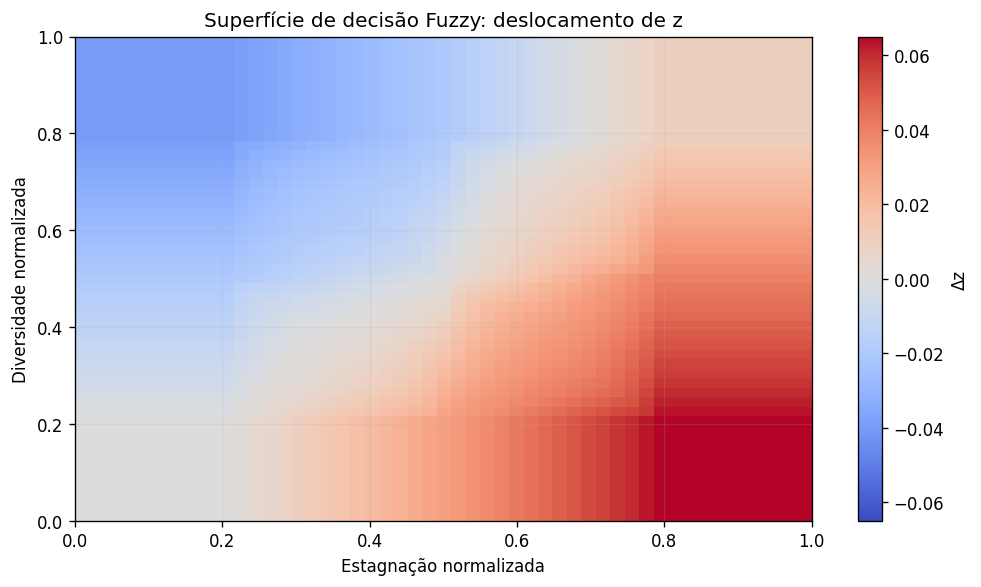

In [5]:
dv=np.linspace(0,1,51);ev=np.linspace(0,1,51)
surf=np.array([[controlador_fuzzy(d,e,0.) for e in ev] for d in dv])
# O ponto base zero e a restrição de não-negatividade ocultariam os deslocamentos negativos.
# Para mostrar a resposta completa, utiliza-se uma referência intermediária (0,075).
surf_delta=np.array([[controlador_fuzzy(d,e,.075)-.075 for e in ev] for d in dv])
fig,ax=plt.subplots(figsize=(8.5,5))
im=ax.imshow(surf_delta,origin='lower',aspect='auto',extent=[0,1,0,1],cmap='coolwarm',vmin=-.065,vmax=.065)
ax.set(xlabel='Estagnação normalizada',ylabel='Diversidade normalizada',title='Superfície de decisão Fuzzy: deslocamento de z')
cb=fig.colorbar(im,ax=ax);cb.set_label('Δz')
fig.tight_layout();fig.savefig(OUT/'02_superficie_controle.png',bbox_inches='tight');plt.show()

## 4. Integração do controlador ao SMA

A rotina a seguir conserva a atualização contínua e a decodificação empregadas no SMA anterior. Na versão fixa, `z_t = z_base`. Na versão adaptativa, o controlador é consultado a cada geração para calcular `z_t`, utilizando a diversidade e a estagnação da população **antes da atualização**.

Para comparabilidade, ambos os métodos utilizam o mesmo número de avaliações reais, o mesmo tamanho da população e as mesmas sementes. As trajetórias aleatórias deixam de coincidir após decisões diferentes de reinicialização, o que é esperado.

In [6]:
# Núcleo de execução do Slime Mould Algorithm (SMA) para minimização.
# A representação de permutação é definida pela função de avaliação externa.
def sma_otimizar(fo, dimensao, populacao=30, avaliacoes=3000, seed=42,
                 z=0.03, controlador=None, janela_estagnacao=12,
                 observador=None, seletor=None):
    """Executa o SMA e retorna melhor fitness, posição, histórico e diagnósticos.

    `controlador(diversidade, estagnacao, z_base)` devolve z da geração.
    `observador(keys, fitness, geracao)` recebe apenas avaliações exatas.
    `seletor(X, restantes)` devolve (fitness_previsto, indices_para_avaliar).
    Sem `seletor`, todos os indivíduos da geração são avaliados pela função objetivo.
    """
    pop, dim = int(populacao), int(dimensao)
    if pop < 3 or dim < 1 or int(avaliacoes) < pop or not 0 <= z <= 1:
        raise ValueError('Dimensões, orçamento ou parâmetros inválidos')
    budget = int(avaliacoes)
    rng = np.random.default_rng(seed)
    X = rng.uniform(0.0, 1.0, (pop, dim))
    melhor_x = np.zeros(dim, dtype=float)
    melhor_y = float('inf')
    usadas = 0
    geracao = 0
    melhor_geracao = 0
    linhas = []
    empate_geracional = []
    reinicios = 0
    if seletor is None:
        total_geracoes = int(np.ceil(budget / pop))
    else:
        lote_estimado = max(1, int(np.ceil(pop * 0.4)))
        total_geracoes = 1 + int(np.ceil((budget-pop) / lote_estimado))

    while usadas < budget:
        geracao += 1
        # Tratamento de limites do código de referência: aplicado antes da avaliação.
        np.clip(X, 0.0, 1.0, out=X)
        empate_geracional.append(float(np.mean([dim-len(np.unique(v)) for v in X])))
        restantes = budget - usadas
        if seletor is None or geracao == 1:
            indices_exatos = np.arange(min(pop, restantes), dtype=int)
            fitness = np.full(pop, np.inf, dtype=float)
        else:
            previstos, indices_exatos = seletor(X, restantes)
            fitness = np.asarray(previstos, dtype=float).copy()
            indices_exatos = np.asarray(indices_exatos, dtype=int)
            if fitness.shape != (pop,) or not np.all(np.isfinite(fitness)):
                raise ValueError('Predições de fitness inválidas')
            if len(indices_exatos) < 1 or len(indices_exatos) > restantes:
                raise ValueError('Quantidade inválida de avaliações exatas')

        for i in indices_exatos:
            fitness[i] = float(fo(X[i]))
            usadas += 1
            if not np.isfinite(fitness[i]):
                raise ValueError('Fitness não finito')
            if observador is not None:
                observador(X[i].copy(), float(fitness[i]), geracao-1)
            if float(fitness[i]) < melhor_y:
                melhor_y = float(fitness[i])
                melhor_x = X[i].copy()
                melhor_geracao = geracao
        if not np.isfinite(melhor_y):
            raise RuntimeError('Melhor fitness não identificado')

        # Entrada da política de controle: diferença média de posições nas permutações.
        diversidade = float(np.mean(np.argsort(X, axis=1, kind='stable') !=
                                   np.argsort(melhor_x, kind='stable')))
        estagnacao = float(min(1.0, max(0, geracao-melhor_geracao) /
                               max(1, int(janela_estagnacao))))
        z_atual = float(np.clip(controlador(diversidade, estagnacao, float(z))
                                 if controlador is not None else z, 0, 1))
        linhas.append(dict(geracao=geracao-1, avaliacoes=usadas,
                           melhor=melhor_y, diversidade=diversidade,
                           estagnacao=estagnacao, z=z_atual,
                           empates_medio=empate_geracional[-1]))
        if usadas >= budget:
            break

        # A ordem do ranking e a matriz de pesos seguem as operações da referência.
        ordem = np.argsort(fitness, kind='stable')
        melhor_atual = float(fitness[ordem[0]])
        pior_atual = float(fitness[ordem[-1]])
        denominador = melhor_atual - pior_atual + np.finfo(float).eps
        W = np.ones_like(X)
        for pos, idx in enumerate(ordem):
            razao = (melhor_atual - float(fitness[idx])) / denominador if melhor_atual != pior_atual else 0.0
            termo = float(np.log10(razao + 1.0))
            sinal = 1.0 if pos + 1 <= pop/2 else -1.0
            for j in range(dim):
                W[idx, j] = 1.0 + sinal * rng.random() * termo

        a = float(np.arctanh(1.0 - geracao / total_geracoes))
        b = float(1.0 - geracao / total_geracoes)
        # Atualização sequencial, usando a mesma matriz de posições.
        for i in range(pop):
            if rng.random() < z_atual:
                X[i, :] = rng.random()  # reinicialização por escalar
                reinicios += 1
            else:
                p = float(np.tanh(abs(float(fitness[i]) - melhor_y)))
                vb = rng.uniform(-a, a, size=dim)
                vc = rng.uniform(-b, b, size=dim)
                for j in range(dim):
                    r = rng.random()
                    A = int(rng.integers(0, pop))
                    B = int(rng.integers(0, pop))
                    if r < p:
                        X[i, j] = melhor_x[j] + vb[j] * (W[i, j] * X[A, j] - X[B, j])
                    else:
                        X[i, j] = vc[j] * X[i, j]
    historico_df = pd.DataFrame(linhas)
    historico = historico_df[['avaliacoes', 'melhor']].to_numpy(dtype=float)
    return dict(fitness=melhor_y, melhor_posicao=melhor_x,
                historico=historico, historico_completo=historico_df,
                cfo=usadas, empates_medio=float(np.mean(empate_geracional)),
                reinicios=reinicios)



def diversidade_permutacoes(X,melhor_x):
    return float(np.mean(np.argsort(X,axis=1,kind='stable')!=np.argsort(melhor_x,kind='stable')))

def executar_sma_controle(engine,parametros,seed,budget,adaptativo=False,fuzzy_cfg=None):
    z_base=float(parametros['z'])
    cfg=fuzzy_cfg or {}
    janela=int(cfg.get('janela_estagnacao',CONFIG['janela_estagnacao']))
    escala_positiva=float(cfg.get('escala_positiva',1.))
    escala_negativa=float(cfg.get('escala_negativa',1.))
    def politica(diversidade,estagnacao,z):
        return controlador_fuzzy(diversidade,estagnacao,z,
                                  CONFIG['intensidade_controle'],escala_positiva,escala_negativa)
    r=sma_otimizar(lambda x:engine.evaluate(x,mode='PFS',objective='Tardiness'),
                   engine.n_jobs,populacao=int(parametros['populacao']),
                   avaliacoes=budget,seed=seed,z=z_base,
                   controlador=politica if adaptativo else None,
                   janela_estagnacao=janela)
    return {'fitness':r['fitness'], 'permutacao':engine.bucket_sort_decode(r['melhor_posicao']),
            'cfo':r['cfo'], 'historico':r['historico_completo']}

for nome,engine in ENGINES.items():
    for adaptativo in (False,True):
        cfg=PARAMETROS_SMA[nome];test_budget=max(120,int(cfg['populacao'])*3)
        r=executar_sma_controle(engine,cfg,12345,test_budget,adaptativo)
        assert r['cfo']==test_budget
        assert np.array_equal(np.sort(r['permutacao']),np.arange(engine.n_jobs))
        assert r['historico']['melhor'].diff().dropna().le(0).all()
        assert r['historico']['z'].between(*CONFIG['intervalo_z']).all()
print('Verificação do solver e do controlador: OK')


Verificação do solver e do controlador: OK


## 5. Sintonia do controlador com Optuna

A sintonia é conduzida separadamente para cada instância. Cada *trial* define uma combinação de valores e executa o SMA Fuzzy com a mesma lista de sementes e o mesmo orçamento de avaliações reais. O Optuna minimiza a **média do Total Tardiness final**; não se utiliza o resultado do conjunto de teste para selecionar parâmetros.

| Parâmetro | Intervalo | Interpretação |
|:--|:--|:--|
| `escala_positiva` | 0,25 a 2,00 | Multiplica consequentes positivos (aumentos de `z`) |
| `escala_negativa` | 0,25 a 2,00 | Multiplica consequentes negativos (reduções de `z`) |
| `janela_estagnacao` | 5 a 30 gerações | Define quando a estagnação normalizada chega a 1 |

**Orçamento completo:** 50 trials por instância × 3 sementes de sintonia × 3.000 avaliações reais = 450.000 avaliações por instância. A comparação final utiliza 20 outras sementes e orçamento idêntico entre métodos. Essa sintonia não modifica as funções de pertinência nem o sinal dos consequentes. O ótimo encontrado é relativo ao espaço investigado.

In [7]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
SINTONIAS=[]; TRIALS=[]; MELHORES_FUZZY={}; ESTUDOS={}
for idx,(nome,engine) in enumerate(ENGINES.items()):
    def funcao_objetivo(trial):
        parametros_fuzzy={
            'escala_positiva':trial.suggest_float('escala_positiva',0.25,2.0),
            'escala_negativa':trial.suggest_float('escala_negativa',0.25,2.0),
            'janela_estagnacao':trial.suggest_int('janela_estagnacao',5,30)
        }
        resultados=[]
        for semente in CONFIG['sementes_sintonia']:
            resultado=executar_sma_controle(engine,PARAMETROS_SMA[nome],semente,
                CONFIG['avaliacoes_sintonia'],adaptativo=True,fuzzy_cfg=parametros_fuzzy)
            resultados.append(resultado['fitness'])
        trial.set_user_attr('desvio',float(np.std(resultados)))
        return float(np.mean(resultados))
    estudo=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(seed=SEMENTE_GLOBAL+idx))
    estudo.optimize(funcao_objetivo,n_trials=CONFIG['trials_optuna'],show_progress_bar=False)
    ESTUDOS[nome]=estudo
    MELHORES_FUZZY[nome]=dict(estudo.best_params)
    SINTONIAS.append({'instancia':nome,'melhor_trial':estudo.best_trial.number,
                      'fitness_medio_sintonia':estudo.best_value,**estudo.best_params})
    quadro=estudo.trials_dataframe(attrs=('number','value','params','state'))
    quadro.insert(0,'instancia',nome);TRIALS.append(quadro)
    print(f'{nome}: melhor score={estudo.best_value:.3f}, trial={estudo.best_trial.number}')
    print('  Configuração selecionada:',estudo.best_params)
SINTONIA=pd.DataFrame(SINTONIAS)
TRIALS_OPTUNA=pd.concat(TRIALS,ignore_index=True)
display(SINTONIA.round(5))
TRIALS_OPTUNA.to_csv(OUT/'trials_optuna_fuzzy.csv',index=False)
SINTONIA.to_csv(OUT/'parametros_fuzzy_selecionados.csv',index=False)
with open(OUT/'melhores_parametros_fuzzy.json','w',encoding='utf-8') as fp:
    json.dump(MELHORES_FUZZY,fp,ensure_ascii=False,indent=2)

Large/Ta001_2.txt: melhor score=6705.333, trial=40
  Configuração selecionada: {'escala_positiva': 1.1085375402148143, 'escala_negativa': 0.6213014503834069, 'janela_estagnacao': 5}
Large/Ta041_3.txt: melhor score=51252.333, trial=42
  Configuração selecionada: {'escala_positiva': 1.9140941811688401, 'escala_negativa': 1.8033719101070624, 'janela_estagnacao': 19}


,instancia,melhor_trial,fitness_medio_sintonia,escala_positiva,escala_negativa,janela_estagnacao
0,Large/Ta001_2.txt,40,6705.33333,1.10854,0.62130,5
1,Large/Ta041_3.txt,42,51252.33333,1.91409,1.80337,19


### 5.1. Histórico e importância dos parâmetros

O primeiro gráfico apresenta o score de cada trial e o melhor valor acumulado: quedas indicam novas configurações superiores na sintonia. O segundo estima a importância relativa dos três parâmetros para a variação do score no espaço amostrado. A importância é uma estimativa estatística, não uma relação causal, e fica mais confiável com maior diversidade de trials.

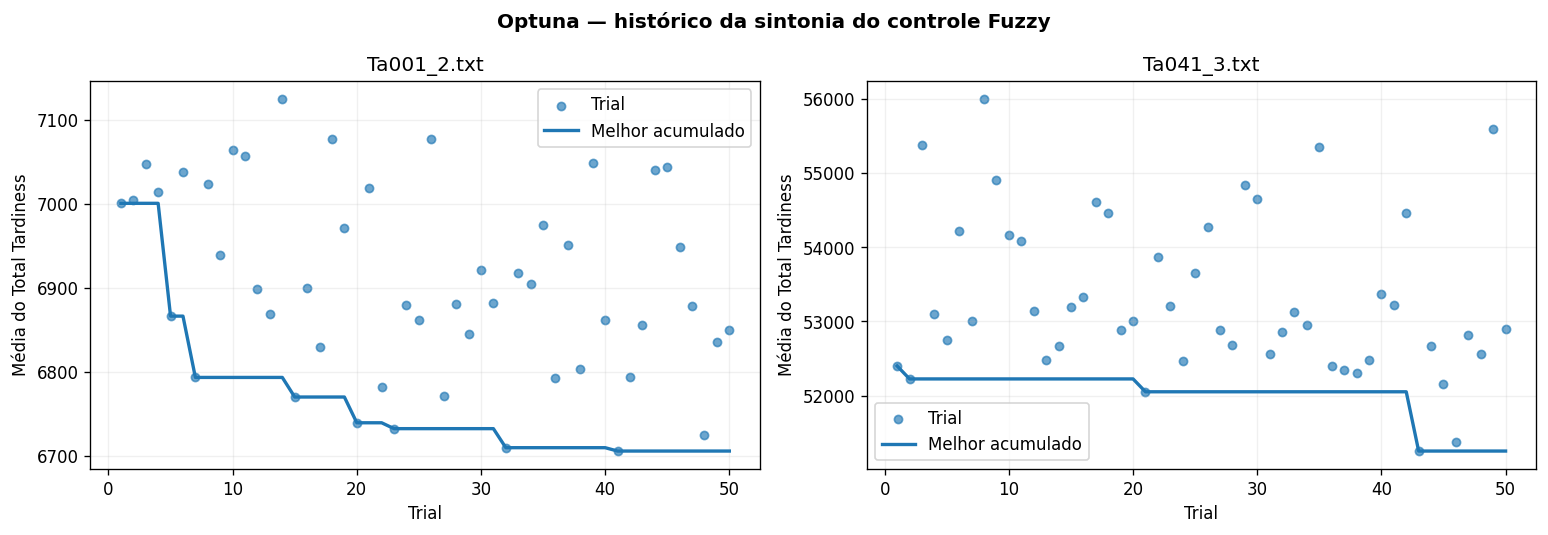

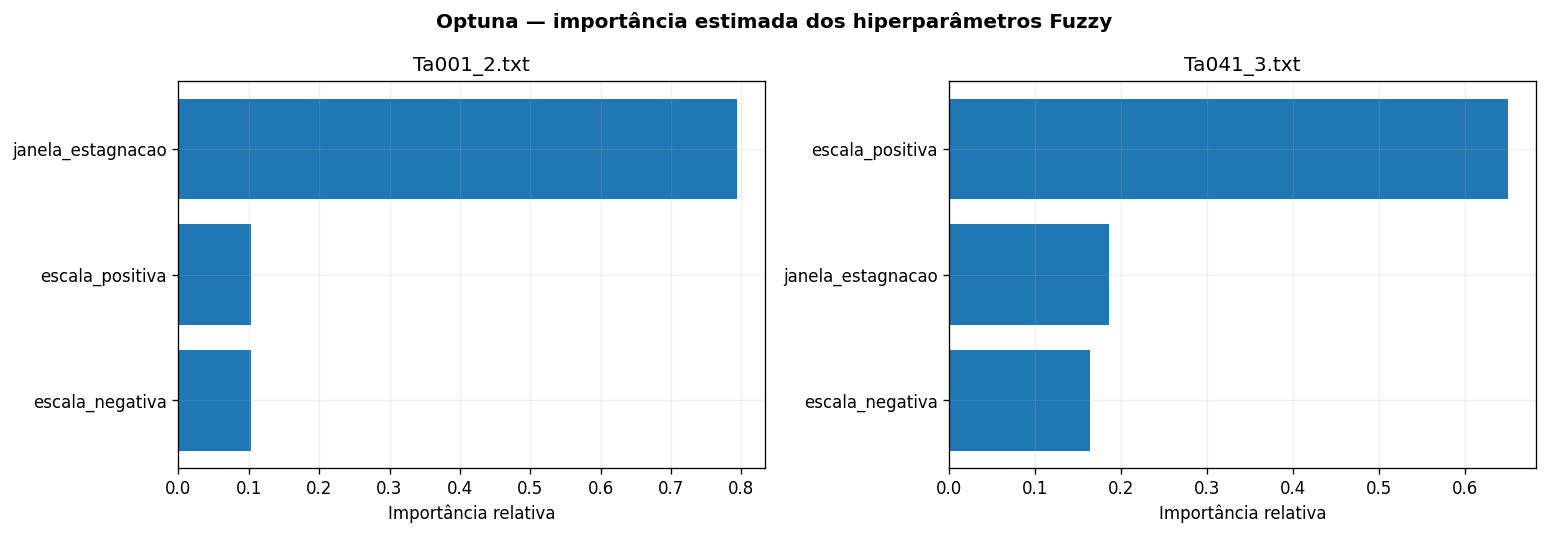

In [8]:
fig,axs=plt.subplots(1,len(INSTANCIAS),figsize=(13,4.5),squeeze=False)
for ax,nome in zip(axs[0],INSTANCIAS):
    estudo=ESTUDOS[nome]
    valores=np.array([t.value for t in estudo.trials],dtype=float)
    ax.scatter(np.arange(1,len(valores)+1),valores,s=24,label='Trial',alpha=.65)
    ax.plot(np.arange(1,len(valores)+1),np.minimum.accumulate(valores),lw=2,label='Melhor acumulado')
    ax.set(title=nome.split('/')[-1],xlabel='Trial',ylabel='Média do Total Tardiness');ax.legend()
fig.suptitle('Optuna — histórico da sintonia do controle Fuzzy',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'08_optuna_historico_fuzzy.png',bbox_inches='tight');plt.show()
fig,axs=plt.subplots(1,len(INSTANCIAS),figsize=(13,4.5),squeeze=False)
for ax,nome in zip(axs[0],INSTANCIAS):
    if len(ESTUDOS[nome].trials)>=8:
        try: importancia=optuna.importance.get_param_importances(ESTUDOS[nome])
        except Exception: importancia={k:np.nan for k in MELHORES_FUZZY[nome]}
    else: importancia={k:np.nan for k in MELHORES_FUZZY[nome]}
    ax.barh(list(importancia.keys()),list(importancia.values()))
    ax.invert_yaxis();ax.set(title=nome.split('/')[-1],xlabel='Importância relativa')
fig.suptitle('Optuna — importância estimada dos hiperparâmetros Fuzzy',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'09_optuna_importancia_fuzzy.png',bbox_inches='tight');plt.show()

### 5.2. Superfícies de decisão antes e depois da sintonia

Os mapas representam o deslocamento `Δz` produzido pelo controlador para diferentes valores de diversidade e estagnação. A comparação permite observar como a sintonia modificou a intensidade das regras, sem alterar as categorias linguísticas.

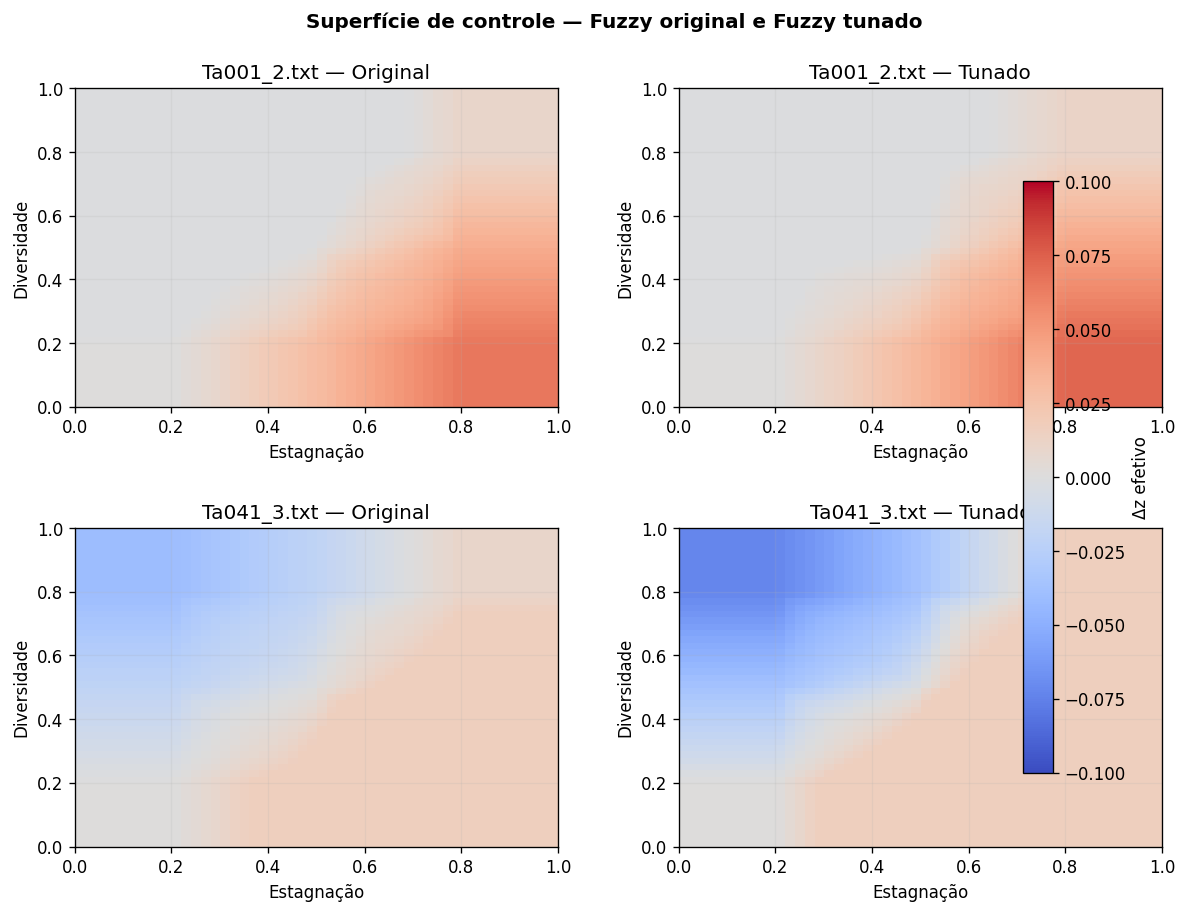

In [9]:
dv=np.linspace(0,1,50);ev=np.linspace(0,1,50)
fig,axs=plt.subplots(len(INSTANCIAS),2,figsize=(12,8),squeeze=False)
for i,nome in enumerate(INSTANCIAS):
    base=PARAMETROS_SMA[nome]['z']
    for j,(rotulo,cf) in enumerate([('Original',{'escala_positiva':1.,'escala_negativa':1.}),
                                    ('Tunado',MELHORES_FUZZY[nome])]):
        z=np.array([[controlador_fuzzy(d,e,base,escala_positiva=cf['escala_positiva'],
                         escala_negativa=cf['escala_negativa'])-base for e in ev] for d in dv])
        im=axs[i,j].imshow(z,extent=[0,1,0,1],origin='lower',aspect='auto',cmap='coolwarm',vmin=-.1,vmax=.1)
        axs[i,j].set(title=f'{nome.split("/")[-1]} — {rotulo}',xlabel='Estagnação',ylabel='Diversidade')
fig.colorbar(im,ax=axs.ravel().tolist(),label='Δz efetivo',shrink=.8)
fig.suptitle('Superfície de controle — Fuzzy original e Fuzzy tunado',fontweight='bold')
fig.subplots_adjust(top=.90,right=.88,hspace=.38,wspace=.25)
fig.savefig(OUT/'10_superficies_fuzzy_original_tunado.png',bbox_inches='tight');plt.show()

## 6. Comparação final em sementes independentes

A comparação inclui **SMA fixo**, **SMA Fuzzy original** e **SMA Fuzzy tunado**. Os três utilizam a mesma `FlowShopEngine`, população, instância, orçamento e sementes. O Fuzzy tunado é inicializado apenas com parâmetros selecionados na etapa anterior. As médias do fitness são calculadas dentro de cada instância.

## 6. Execução experimental

São realizadas execuções independentes com as sementes indicadas no protocolo. O número de avaliações reais (`CFO`) é fixo. Os dados armazenados incluem fitness final, tempo, permutação, trajetória da melhor solução, diversidade, estagnação e parâmetro ajustado.

In [10]:
REGISTROS=[];HISTORICOS=[]
METODOS=['SMA fixo','SMA Fuzzy original','SMA Fuzzy tunado']
for nome,engine in ENGINES.items():
    print(f'\nInstância: {nome} — {engine.n_jobs} trabalhos, {engine.n_machines} máquinas')
    for seed in CONFIG['sementes']:
        for metodo in METODOS:
            flag=(metodo!='SMA fixo')
            cfg=MELHORES_FUZZY[nome] if metodo=='SMA Fuzzy tunado' else None
            t0=time.perf_counter()
            res=executar_sma_controle(engine,PARAMETROS_SMA[nome],seed,
                CONFIG['avaliacoes'],flag,fuzzy_cfg=cfg)
            tempo=time.perf_counter()-t0
            REGISTROS.append({'instancia':nome,'metodo':metodo,'semente':seed,
                'total_tardiness':res['fitness'],'tempo_s':tempo,'avaliacoes':res['cfo'],
                'permutacao':','.join(map(str,res['permutacao']))})
            h=res['historico'].copy();h['instancia']=nome;h['metodo']=metodo;h['semente']=seed
            HISTORICOS.append(h)
    print('  Execuções concluídas:',len(METODOS)*len(CONFIG['sementes']))
EXECUCOES=pd.DataFrame(REGISTROS)
HIST=pd.concat(HISTORICOS,ignore_index=True)
EXECUCOES.to_csv(OUT/'execucoes_individuais.csv',index=False)
HIST.to_csv(OUT/'trajetorias_geracionais.csv',index=False)
display(EXECUCOES.groupby(['instancia','metodo'])[['total_tardiness','tempo_s','avaliacoes']].mean().round(3))


Instância: Large/Ta001_2.txt — 20 trabalhos, 5 máquinas
  Execuções concluídas: 60

Instância: Large/Ta041_3.txt — 50 trabalhos, 10 máquinas
  Execuções concluídas: 60


total_tardiness  tempo_s  avaliacoes
instancia         metodo                                                  
Large/Ta001_2.txt SMA Fuzzy original          6853.10    0.783      3000.0
                  SMA Fuzzy tunado            6893.00    0.783      3000.0
                  SMA fixo                    6922.40    0.769      3000.0
Large/Ta041_3.txt SMA Fuzzy original         53595.05    2.066      3000.0
                  SMA Fuzzy tunado           53503.70    2.089      3000.0
                  SMA fixo                   53426.05    2.034      3000.0

## 7. Evolução temporal do controle adaptativo

As figuras seguintes mostram, em cada instância, a trajetória de `z` durante uma execução representativa e os estados que justificam sua atualização. A linha tracejada representa o valor estático obtido pelo Optuna.

**Interpretação:** aumento de `z` indica uma resposta de maior exploração; redução de `z` indica menor probabilidade de reinicialização. O gráfico também permite confirmar que o controlador foi consultado a cada geração, como exigido no protocolo.

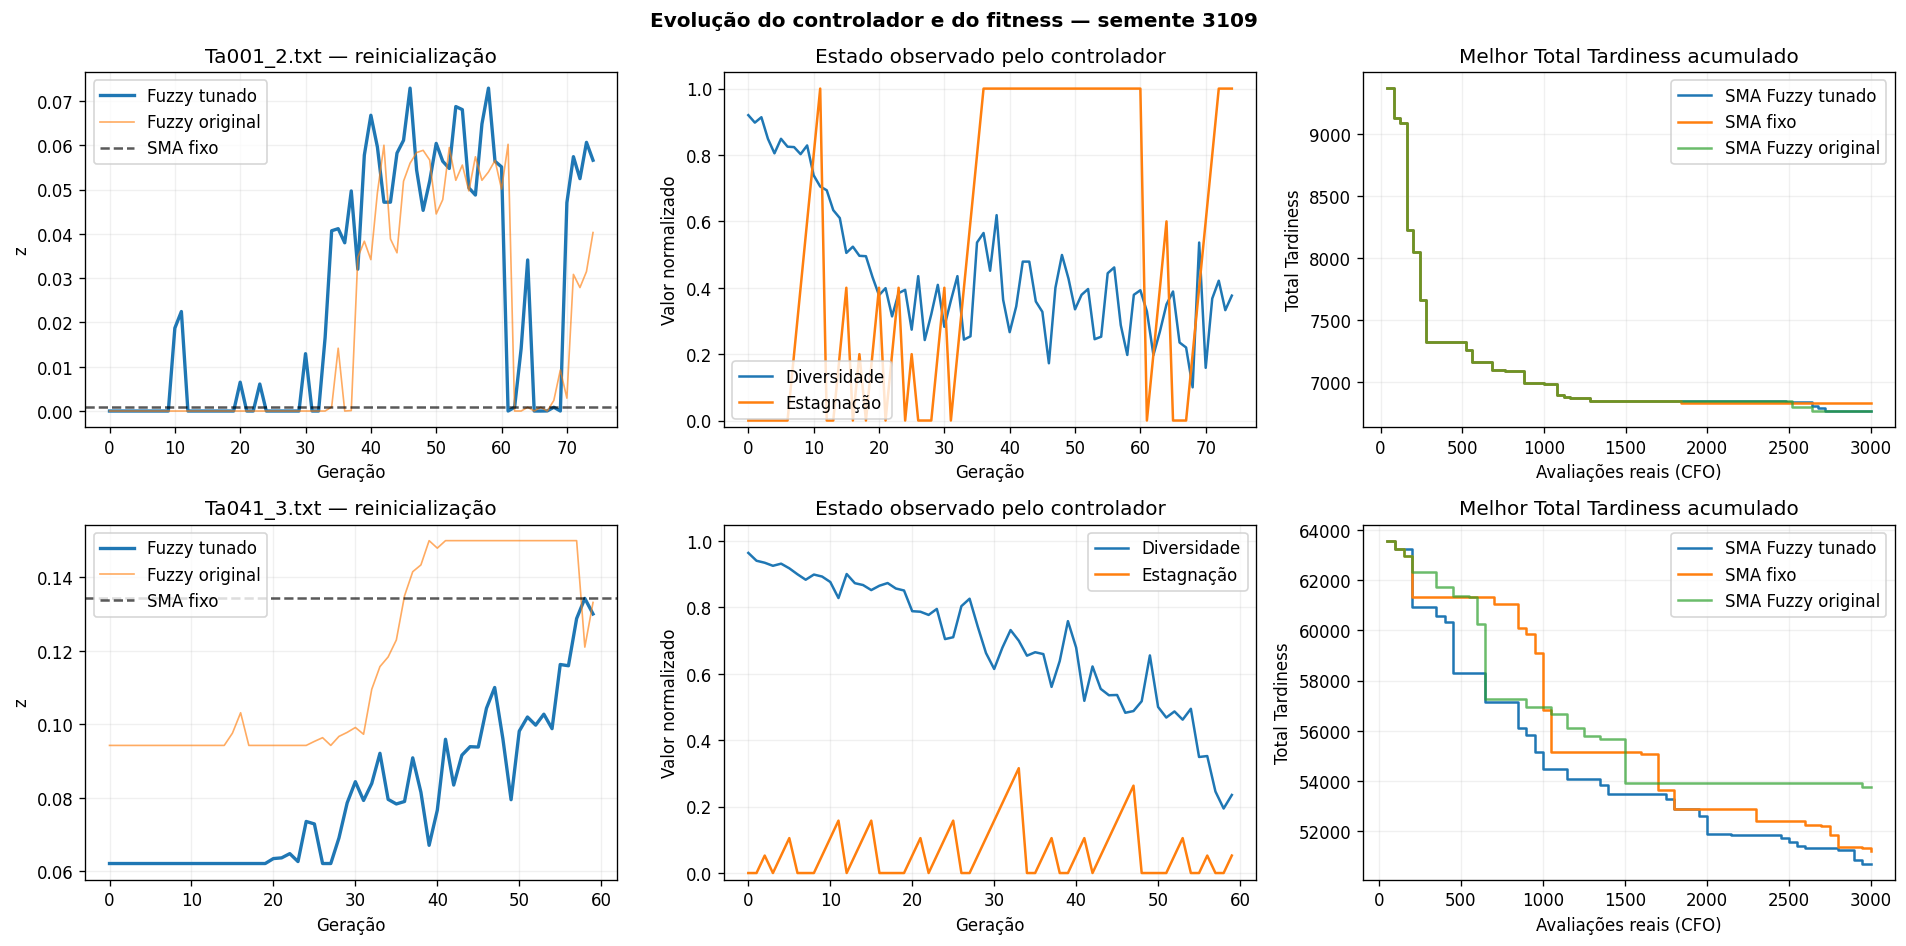

In [11]:
seed=CONFIG['sementes'][0]
fig,axs=plt.subplots(2,3,figsize=(16,8))
for linha,nome in enumerate(INSTANCIAS):
    h=HIST[(HIST.instancia==nome)&(HIST.metodo=='SMA Fuzzy tunado')&(HIST.semente==seed)]
    hf=HIST[(HIST.instancia==nome)&(HIST.metodo=='SMA fixo')&(HIST.semente==seed)]
    ho=HIST[(HIST.instancia==nome)&(HIST.metodo=='SMA Fuzzy original')&(HIST.semente==seed)]
    axs[linha,0].plot(h.geracao,h.z,label='Fuzzy tunado',lw=2)
    axs[linha,0].plot(ho.geracao,ho.z,label='Fuzzy original',lw=1,alpha=.65)
    axs[linha,0].axhline(PARAMETROS_SMA[nome]['z'],ls='--',color='black',alpha=.65,label='SMA fixo')
    axs[linha,0].set(title=f'{nome.split("/")[-1]} — reinicialização',xlabel='Geração',ylabel='z');axs[linha,0].legend()
    axs[linha,1].plot(h.geracao,h.diversidade,label='Diversidade')
    axs[linha,1].plot(h.geracao,h.estagnacao,label='Estagnação')
    axs[linha,1].set(title='Estado observado pelo controlador',xlabel='Geração',ylabel='Valor normalizado',ylim=(-.02,1.05));axs[linha,1].legend()
    axs[linha,2].step(h.avaliacoes,h.melhor,where='post',label='SMA Fuzzy tunado')
    axs[linha,2].step(hf.avaliacoes,hf.melhor,where='post',label='SMA fixo')
    axs[linha,2].step(ho.avaliacoes,ho.melhor,where='post',label='SMA Fuzzy original',alpha=.7)
    axs[linha,2].set(title='Melhor Total Tardiness acumulado',xlabel='Avaliações reais (CFO)',ylabel='Total Tardiness');axs[linha,2].legend()
fig.suptitle(f'Evolução do controlador e do fitness — semente {seed}',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'03_evolucao_fuzzy.png',bbox_inches='tight');plt.show()

### 8.1. Distribuição dos valores de `z` e sensibilidade à instância

A distribuição agrega todas as execuções do SMA Fuzzy. Como `z_base` e o comportamento da população variam entre as instâncias, a amplitude observada pode ser diferente mesmo com as mesmas regras.

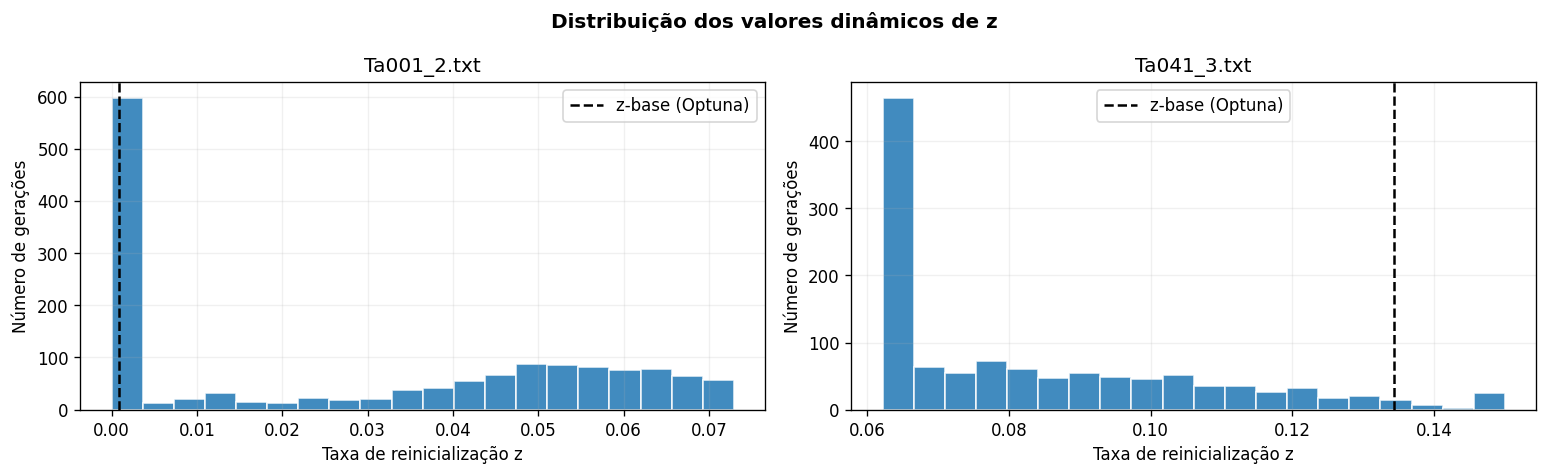

In [12]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax,nome in zip(axs,INSTANCIAS):
    hs=HIST[(HIST.instancia==nome)&(HIST.metodo=='SMA Fuzzy tunado')&(HIST.geracao>0)]
    ax.hist(hs.z,bins=20,edgecolor='white',alpha=.85)
    ax.axvline(PARAMETROS_SMA[nome]['z'],ls='--',color='black',label='z-base (Optuna)')
    ax.set(title=nome.split('/')[-1],xlabel='Taxa de reinicialização z',ylabel='Número de gerações')
    ax.legend()
fig.suptitle('Distribuição dos valores dinâmicos de z',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'04_distribuicao_z.png',bbox_inches='tight');plt.show()

## 8. Comparação de qualidade e custo computacional

O desempenho é avaliado com o mesmo número de avaliações reais por execução. As médias são comparadas **dentro de cada instância**, pois os valores absolutos do Total Tardiness não têm a mesma escala entre problemas diferentes.

\[
\mathrm{Ganho}_{\%}=100\frac{\overline{TT}_{fixo}-\overline{TT}_{Fuzzy}}{\overline{TT}_{fixo}}.
\]

Ganhos positivos indicam menor atraso médio para a versão adaptativa. Tempos maiores indicam custo adicional do controlador.

In [13]:
RESUMO=EXECUCOES.groupby(['instancia','metodo']).agg(
    media=('total_tardiness','mean'),desvio=('total_tardiness','std'),
    melhor=('total_tardiness','min'),pior=('total_tardiness','max'),
    tempo_medio_s=('tempo_s','mean'),cfo=('avaliacoes','mean')).reset_index()
RESUMO['desvio']=RESUMO['desvio'].fillna(0.)
comparacao=[]
for nome in INSTANCIAS:
    base=RESUMO[(RESUMO.instancia==nome)&(RESUMO.metodo=='SMA fixo')].iloc[0]
    for metodo in METODOS[1:]:
        outro=RESUMO[(RESUMO.instancia==nome)&(RESUMO.metodo==metodo)].iloc[0]
        comparacao.append({'instancia':nome,'metodo':metodo,'media_fixo':base.media,
            'media_comparado':outro.media,'ganho_pct':100*(base.media-outro.media)/base.media if base.media else np.nan,
            'tempo_fixo_s':base.tempo_medio_s,'tempo_comparado_s':outro.tempo_medio_s,
            'sobrecusto_tempo_pct':100*(outro.tempo_medio_s/base.tempo_medio_s-1)})
COMPARACAO=pd.DataFrame(comparacao)
RESUMO.to_csv(OUT/'resumo_completo.csv',index=False)
COMPARACAO.to_csv(OUT/'comparacao_fixo_fuzzy.csv',index=False)
print('Resultados por instância e método:');display(RESUMO.round(3))
print('Comparações relativas ao método fixo:');display(COMPARACAO.round(3))

Resultados por instância e método:


,instancia,metodo,media,desvio,melhor,pior,tempo_medio_s,cfo
0,Large/Ta001_2.txt,SMA Fuzzy original,6853.10,163.269,6602.0,7176.0,0.783,3000.0
1,Large/Ta001_2.txt,SMA Fuzzy tunado,6893.00,258.586,6595.0,7788.0,0.783,3000.0
2,Large/Ta001_2.txt,SMA fixo,6922.40,180.650,6693.0,7447.0,0.769,3000.0
3,Large/Ta041_3.txt,SMA Fuzzy original,53595.05,1834.685,50089.0,56933.0,2.066,3000.0
4,Large/Ta041_3.txt,SMA Fuzzy tunado,53503.70,1492.990,50225.0,55521.0,2.089,3000.0
5,Large/Ta041_3.txt,SMA fixo,53426.05,2094.136,50038.0,57901.0,2.034,3000.0


Comparações relativas ao método fixo:


,instancia,metodo,media_fixo,media_comparado,ganho_pct,tempo_fixo_s,tempo_comparado_s,sobrecusto_tempo_pct
0,Large/Ta001_2.txt,SMA Fuzzy original,6922.40,6853.10,1.001,0.769,0.783,1.795
1,Large/Ta001_2.txt,SMA Fuzzy tunado,6922.40,6893.00,0.425,0.769,0.783,1.886
2,Large/Ta041_3.txt,SMA Fuzzy original,53426.05,53595.05,-0.316,2.034,2.066,1.583
3,Large/Ta041_3.txt,SMA Fuzzy tunado,53426.05,53503.70,-0.145,2.034,2.089,2.701


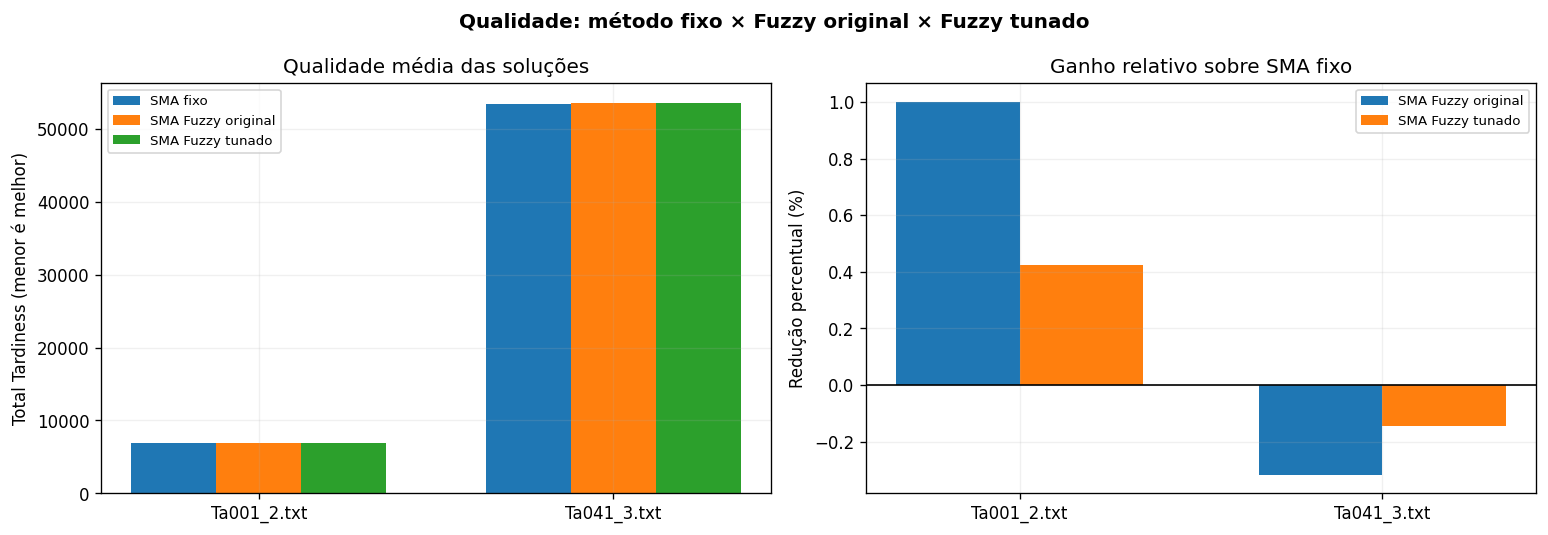

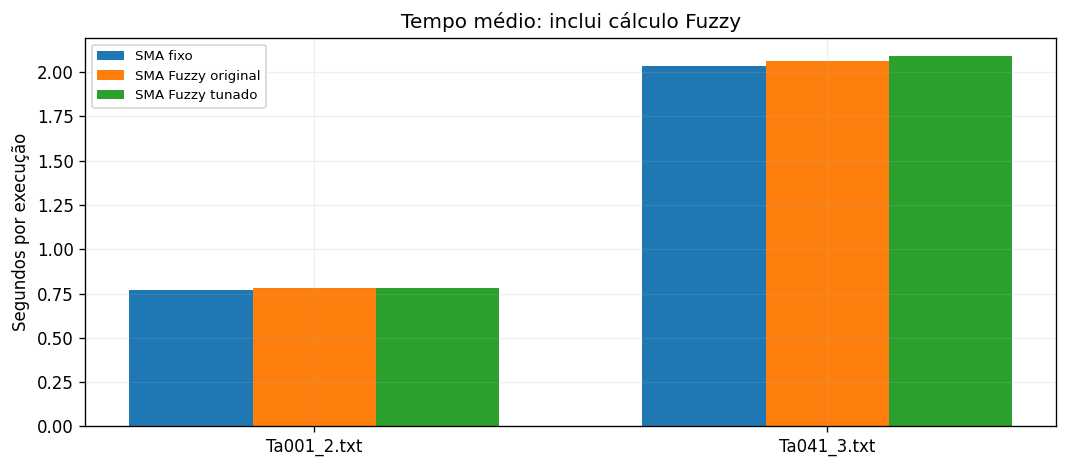

In [14]:
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
nomes=[x.split('/')[-1] for x in INSTANCIAS];x=np.arange(len(nomes));larg=.24
for k,met in enumerate(METODOS):
    aux=RESUMO[RESUMO.metodo==met].set_index('instancia').loc[INSTANCIAS]
    axs[0].bar(x+(k-1)*larg,aux.media,width=larg,label=met)
axs[0].set(xticks=x,xticklabels=nomes,title='Qualidade média das soluções',ylabel='Total Tardiness (menor é melhor)');axs[0].legend(fontsize=8)
for k,met in enumerate(METODOS[1:]):
    aux=COMPARACAO[COMPARACAO.metodo==met].set_index('instancia').loc[INSTANCIAS]
    axs[1].bar(x+(k-.5)*.34,aux.ganho_pct,width=.34,label=met)
axs[1].axhline(0,color='black',lw=1)
axs[1].set(xticks=x,xticklabels=nomes,title='Ganho relativo sobre SMA fixo',ylabel='Redução percentual (%)');axs[1].legend(fontsize=8)
fig.suptitle('Qualidade: método fixo × Fuzzy original × Fuzzy tunado',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'05_qualidade_solucoes.png',bbox_inches='tight');plt.show()
fig,ax=plt.subplots(figsize=(9,4))
for k,met in enumerate(METODOS):
    aux=RESUMO[RESUMO.metodo==met].set_index('instancia').loc[INSTANCIAS]
    ax.bar(x+(k-1)*larg,aux.tempo_medio_s,width=larg,label=met)
ax.set(xticks=x,xticklabels=nomes,title='Tempo médio: inclui cálculo Fuzzy',ylabel='Segundos por execução')
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/'06_tempo_execucao.png',bbox_inches='tight');plt.show()

### 8.1. Variabilidade entre sementes

O boxplot apresenta a distribuição do fitness final. Caixas mais baixas e concentradas indicam melhor qualidade e menor dispersão. O gráfico deve ser interpretado em conjunto com a média e o desvio-padrão, especialmente em instâncias com poucos resultados distintos.

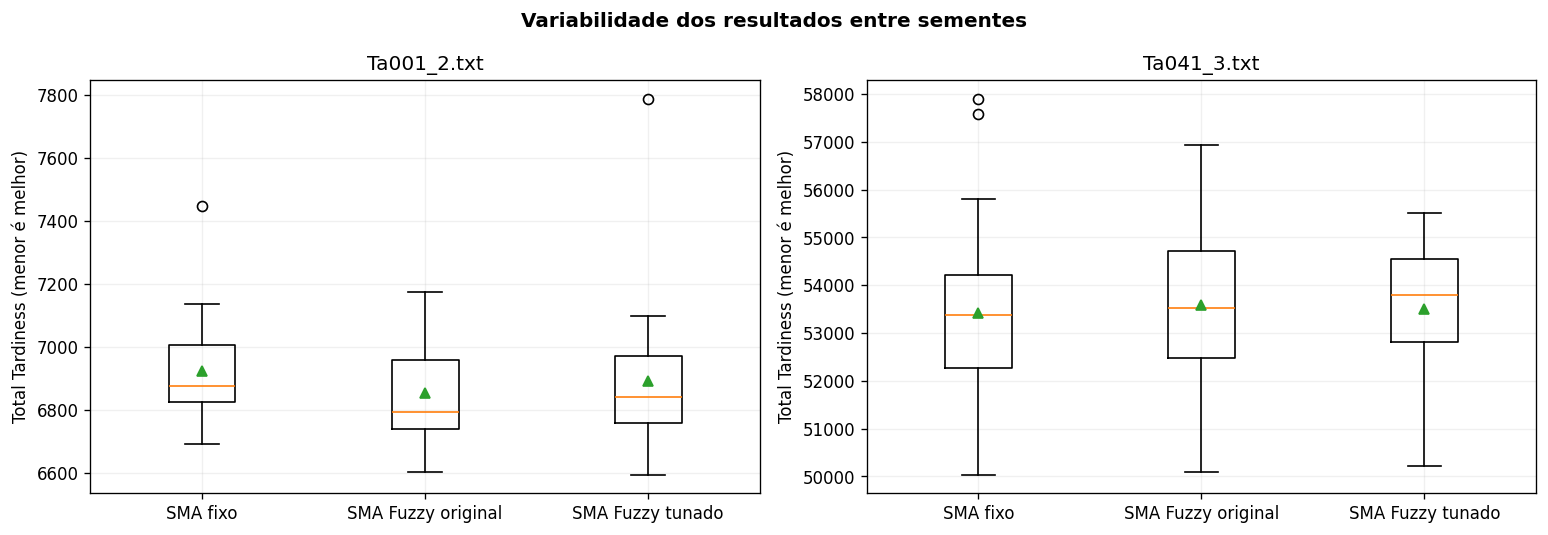

In [15]:
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
for ax,nome in zip(axs,INSTANCIAS):
    vals=[EXECUCOES[(EXECUCOES.instancia==nome)&(EXECUCOES.metodo==met)].total_tardiness.values
          for met in METODOS]
    ax.boxplot(vals,tick_labels=METODOS,showmeans=True)
    ax.set(title=nome.split('/')[-1],ylabel='Total Tardiness (menor é melhor)')
fig.suptitle('Variabilidade dos resultados entre sementes',fontweight='bold')
fig.tight_layout();fig.savefig(OUT/'07_boxplots.png',bbox_inches='tight');plt.show()

## 9. Análise estatística pareada

As mesmas sementes são utilizadas nos dois métodos. O teste de Wilcoxon de duas caudas é aplicado às diferenças de fitness final, com a hipótese nula de diferença central igual a zero. O número de pares é informado; significância estatística não deve ser confundida com relevância prática.

As medições de tempo são informadas descritivamente, pois sua variação também depende do ambiente de execução.

In [16]:
ESTATISTICAS=[]
for nome in INSTANCIAS:
    pivot=EXECUCOES[EXECUCOES.instancia==nome].pivot(index='semente',columns='metodo',values='total_tardiness')
    for metodo in METODOS[1:]:
        dif=(pivot['SMA fixo']-pivot[metodo]).to_numpy()
        if len(dif)>=6 and np.any(dif!=0):
            p=float(wilcoxon(dif,alternative='two-sided',zero_method='wilcox').pvalue)
        else:p=np.nan
        ESTATISTICAS.append({'instancia':nome,'metodo':metodo,'pares':len(dif),
            'vitorias_comparado':int((dif>0).sum()),'empates':int((dif==0).sum()),
            'vitorias_fixo':int((dif<0).sum()),'diferenca_media_fixo_menos_comparado':float(dif.mean()),
            'wilcoxon_p_bilateral':p})
ESTATISTICAS=pd.DataFrame(ESTATISTICAS)
# Correção de Holm dentro de cada instância para as duas comparações versus fixo.
from statsmodels.stats.multitest import multipletests
ESTATISTICAS['p_holm']=np.nan
for nome in INSTANCIAS:
    ids=ESTATISTICAS.index[(ESTATISTICAS.instancia==nome)&ESTATISTICAS.wilcoxon_p_bilateral.notna()]
    if len(ids):ESTATISTICAS.loc[ids,'p_holm']=multipletests(ESTATISTICAS.loc[ids,'wilcoxon_p_bilateral'],method='holm')[1]
ESTATISTICAS.to_csv(OUT/'testes_estatisticos.csv',index=False)
display(ESTATISTICAS.round(5))

,instancia,metodo,pares,vitorias_comparado,empates,vitorias_fixo,diferenca_media_fixo_menos_comparado,wilcoxon_p_bilateral,p_holm
0,Large/Ta001_2.txt,SMA Fuzzy original,20,13,1,6,69.30,0.13124,0.26248
1,Large/Ta001_2.txt,SMA Fuzzy tunado,20,10,0,10,29.40,0.47491,0.47491
2,Large/Ta041_3.txt,SMA Fuzzy original,20,8,0,12,-169.00,0.81236,1.00000
3,Large/Ta041_3.txt,SMA Fuzzy tunado,20,10,0,10,-77.65,0.81236,1.00000


## 10. Discussão e conclusão experimental

Esta seção sintetiza automaticamente a comparação das três variantes, sem antecipar superioridade de qualquer método. A qualidade, o custo computacional e o comportamento temporal do controlador são analisados separadamente.

In [17]:
for nome in INSTANCIAS:
    print('\n'+'='*72+'\nINSTÂNCIA:',nome)
    print('Configuração do SMA:',PARAMETROS_SMA[nome])
    print('Optuna atual (Fuzzy):',MELHORES_FUZZY[nome])
    for metodo in METODOS[1:]:
        r=COMPARACAO[(COMPARACAO.instancia==nome)&(COMPARACAO.metodo==metodo)].iloc[0]
        es=ESTATISTICAS[(ESTATISTICAS.instancia==nome)&(ESTATISTICAS.metodo==metodo)].iloc[0]
        hs=HIST[(HIST.instancia==nome)&(HIST.metodo==metodo)&(HIST.geracao>0)]
        print(f'\n{metodo}: Total Tardiness médio = {r.media_comparado:,.2f}; fixo = {r.media_fixo:,.2f}.')
        print(f'Ganho médio = {r.ganho_pct:+.3f}%; sobrecusto médio de tempo = {r.sobrecusto_tempo_pct:+.2f}%.')
        print(f'z observado: mín. {hs.z.min():.4f}; média {hs.z.mean():.4f}; máx. {hs.z.max():.4f}.')
        print(f'Vitórias {int(es.vitorias_comparado)}; empates {int(es.empates)}; derrotas {int(es.vitorias_fixo)}.')
        print('Wilcoxon p Holm:',round(es.p_holm,5) if np.isfinite(es.p_holm) else 'não calculado')
        print('Resultado:', 'redução do atraso médio observada.' if r.ganho_pct>0 else 'sem redução do atraso médio.')
print('\nLIMITAÇÕES: dois problemas previamente analisados; avaliação exploratória com novas sementes;')
print('sintonia do controlador específica por instância; custo de sintonia excluído do tempo médio do solver.')


INSTÂNCIA: Large/Ta001_2.txt
Configuração do SMA: {'populacao': 40, 'z': 0.0008499388875837788}
Optuna atual (Fuzzy): {'escala_positiva': 1.1085375402148143, 'escala_negativa': 0.6213014503834069, 'janela_estagnacao': 5}

SMA Fuzzy original: Total Tardiness médio = 6,853.10; fixo = 6,922.40.
Ganho médio = +1.001%; sobrecusto médio de tempo = +1.79%.
z observado: mín. 0.0000; média 0.0176; máx. 0.0658.
Vitórias 13; empates 1; derrotas 6.
Wilcoxon p Holm: 0.26248
Resultado: redução do atraso médio observada.

SMA Fuzzy tunado: Total Tardiness médio = 6,893.00; fixo = 6,922.40.
Ganho médio = +0.425%; sobrecusto médio de tempo = +1.89%.
z observado: mín. 0.0000; média 0.0286; máx. 0.0729.
Vitórias 10; empates 0; derrotas 10.
Wilcoxon p Holm: 0.47491
Resultado: redução do atraso médio observada.

INSTÂNCIA: Large/Ta041_3.txt
Configuração do SMA: {'populacao': 50, 'z': 0.13428290269269394}
Optuna atual (Fuzzy): {'escala_positiva': 1.9140941811688401, 'escala_negativa': 1.8033719101070624, '

## 11. Arquivos e reprodutibilidade

Os gráficos são exibidos no notebook e salvos como arquivos PNG. As tabelas de execuções, trajetórias do controlador e análises estatísticas são exportadas em CSV. Um manifesto JSON registra as instâncias, as sementes, os parâmetros fixos e as regras Fuzzy.

**Arquivos principais:** `execucoes_individuais.csv`, `trajetorias_geracionais.csv`, `comparacao_fixo_fuzzy.csv`, `testes_estatisticos.csv` e os gráficos `01` a `07`.

In [18]:
MANIFESTO={
    'titulo':'Semana 5 — Controle Fuzzy Adaptativo do SMA com Sintonia Optuna',
    'formulacao':'Permutation Flow Shop, minimização do Total Tardiness',
    'instancias':INSTANCIAS,
    'optuna_semana4':PARAMETROS_SMA,
    'optuna_fuzzy':MELHORES_FUZZY,
    'config':CONFIG,
    'entradas':['diversidade de permutações','estagnação em gerações'],
    'saida':'z_t: probabilidade de reinicialização por geração',
    'inferência':'Sugeno ordem zero; AND=min; agregação=média ponderada',
    'base_regras':REGRAS.to_dict(),
    'conjuntos_sintonia_teste_independentes':True,
    'observacao':'Avaliador exato preservado; surrogate não utilizado na comparação isolada.'
}
with open(OUT/'manifesto.json','w',encoding='utf-8') as f:
    json.dump(MANIFESTO,f,indent=2,ensure_ascii=False)
print('Resultados salvos em:',OUT)
for arq in sorted(OUT.iterdir()):
    if arq.is_file():print(' •',arq.name)

Resultados salvos em: /kaggle/working/semana5_fuzzy_optuna
 • 01_funcoes_pertinencia.png
 • 02_superficie_controle.png
 • 03_evolucao_fuzzy.png
 • 04_distribuicao_z.png
 • 05_qualidade_solucoes.png
 • 06_tempo_execucao.png
 • 07_boxplots.png
 • 08_optuna_historico_fuzzy.png
 • 09_optuna_importancia_fuzzy.png
 • 10_superficies_fuzzy_original_tunado.png
 • comparacao_fixo_fuzzy.csv
 • execucoes_individuais.csv
 • manifesto.json
 • melhores_parametros_fuzzy.json
 • parametros_fuzzy_selecionados.csv
 • resumo_completo.csv
 • testes_estatisticos.csv
 • trajetorias_geracionais.csv
 • trials_optuna_fuzzy.csv
